In [1]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
pth_mod_inh = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/models/fs_internrn_neuron/mod'
pth_data = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data/l23'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/figures/l23_tuning/'
# import os
# os.mkdir(figpth)

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_cells_dev/utils')
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, Ih_condu_apical, distribute_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial
from scipy.signal import find_peaks
from hnn_core.viz import plot_cell_morphology

import os
import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit

import pickle
import pandas as pd

h.load_file('stdrun.hoc')

from hay_mechs_utils import linear_gbar

plt.rcParams['svg.fonttype'] = 'none'
# Set global font sizes
plt.rcParams['font.size'] = 10          # Default text size
plt.rcParams['axes.titlesize'] = 10      # Title size
plt.rcParams['axes.labelsize'] = 10      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 10    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 10     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 10     # Legend text

In [2]:
model_params = {'soma': {'NaTs2_t_32d': 20_400e-4,
                                'SKv3_1': 6_930e-4,
                                'Nap_Et2': 1e-4/2,
                                'Ca_HVA': 9.92e-04,
                                'Ca_LVAst': 34.3e-4*0.1,
                                
                                #'SK_E2': 0.099433/2*0.001,
                                'pas': 1.0 / 10000.0,
                                'Ih': 0.000080*2,
                                'Im': 8e-3*0.01},
                        'basal': {'NaTs2_t_32d': 0.008009*0.01,#partial(linear_gbar,0.008009/2,0,255),
                                  'SKv3_1': 0.000513*0.01,#partial(linear_gbar,0,6_930e-4*0.1,255),
                                  'Ih': 0.00008,
                                  'pas':  1.0 / 10000.0},
                        'dend': {'NaTa_t_32d': 0.008009*0.001*0,
                                'SKv3_1': 0.000513*0.1*0,
                                'Ca_HVA': 2.78e-5*0, #partial(hotzone_gbar, 2.78e-5, [500, 600], 1),
                                'Ca_LVAst': 93.5e-6*0, #partial(hotzone_gbar, 93.5e-6, [500, 600], 1),
                                'pas': 1.0 /37000.0*0,
                                'SK_E2': 0.099433/5*0,
                                'Ih': 0.000080*0.5*0, #{'gbar': 0.000080*0.5, 'offset': -0.869600, 'slope':2.087-0.5, 'factor_exp':1/323},
                                'Im': 8e-3*0,
                                'CaDynamics_E2': {'decay': 342.544232, 'gamma': 0.000533*2.7}},
                        'e_pas': -75}


section_params, end_pts, cell_tree = l2_params()

v_init = {'soma': -73.80743362884836,
        'basal_1': -73.81653134136943,
        'basal_2': -73.84322008805566,
        'basal_3': -73.84322008805566,
        'apical_oblique': -73.84035796710533,
        'apical_trunk': -73.81180969517457,
        'apical_1': -73.81418846860171,
        'apical_tuft': -73.81207265184752}

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)


In [3]:
with open(os.path.join(pth_data,'ephys_l2.pkl'), 'rb') as f:
    l2_allen = pickle.load(f)

with open(os.path.join(pth_data,'ephys_l3.pkl'), 'rb') as f:
    l3_allen = pickle.load(f)

# l2_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l2.csv'))
# l3_allen = pd.read_csv(os.path.join(pth_data, 'ephys_l3.csv'))

# convert AP width to ms

l2_allen.ap_width *= 1000
l3_allen.ap_width *= 1000# 

ephys_measures = dict()

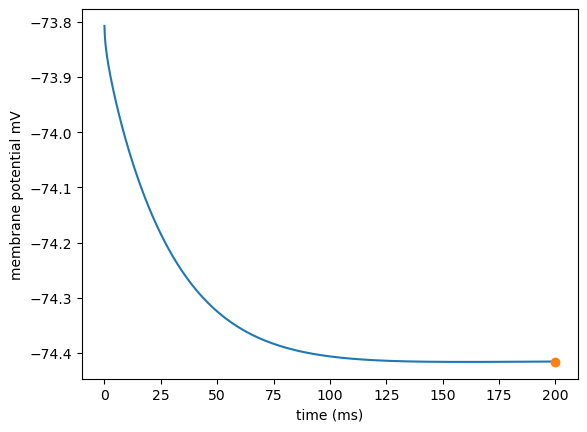

In [4]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = 0.01
h.finitialize()
h.continuerun(200 * ms)

fig, ax = plt.subplots()

# RMP
ephys_measures['RMP'] = soma_v[-3]

ax.plot(t.as_numpy(), soma_v.as_numpy())
ax.set_ylabel('membrane potential mV')
ax.set_xlabel('time (ms)')

ax.plot(t[-3],soma_v[-3], 'o', color='tab:orange')

fig.savefig(os.path.join(figpth, 'RMP_l23.png'))

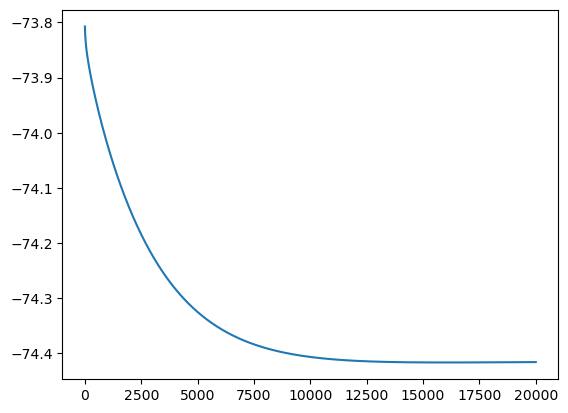

In [5]:
plt.plot(soma_v.as_numpy())

In [6]:
np.min(soma_v.as_numpy())

np.float64(-74.41635461903935)

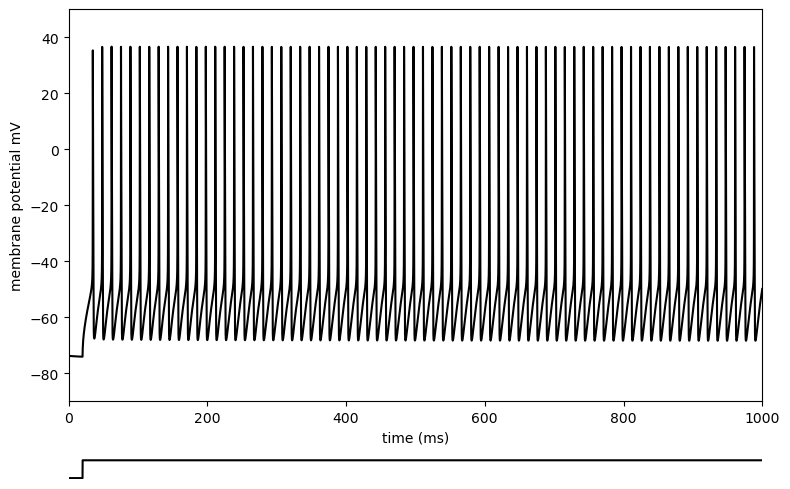

In [7]:
# add stimulation

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = .7
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1020 * ms)

fig, ax = plt.subplots(2,1, height_ratios=[1, 0.05],figsize=(8,5))

ax[1].plot(t,clamp_current.as_numpy()*2, color='k')
ax[1].set_axis_off()
ax[0].plot(t,soma_v, color='k')
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel('membrane potential mV')
ax[0].set_ylim([-90, 50])
ax[0].set_xlim([0, 1000])
ax[1].set_xlim([0, 1000])

fig.tight_layout()

fig.savefig(os.path.join(figpth, 'continuous_clamp.png'))
fig.savefig(os.path.join(figpth, 'continuous_clamp.svg'))

# inhibitory neurons are extremely excitable!


In [8]:
# ISI
from scipy.signal import find_peaks
aps = find_peaks(soma_v,height=0)[0]


ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))



In [9]:
ephys_measures['first_isi'] - np.mean(l2_allen['first_isi'].dropna())

np.float64(-40.245394736835216)

In [10]:
ephys_measures['mean_isi']

np.float64(13.619583333321522)

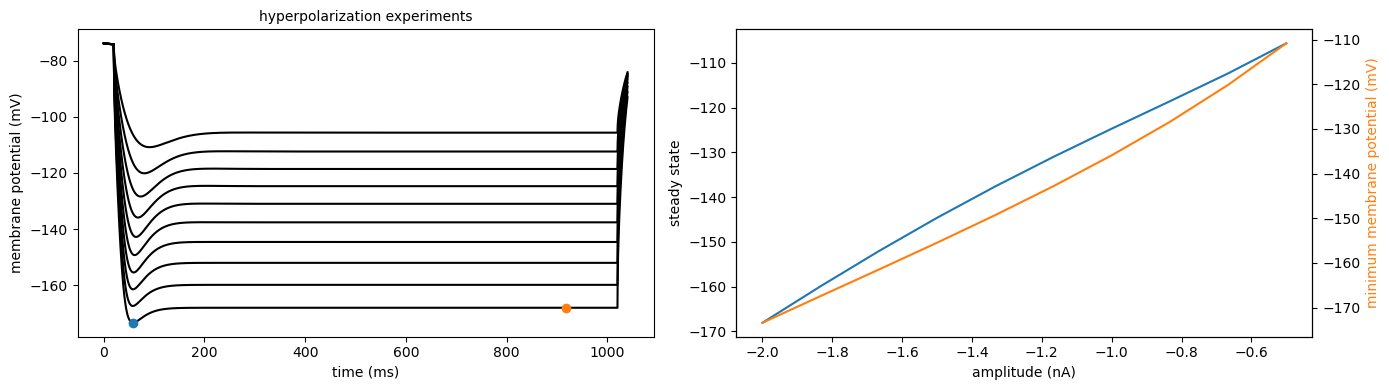

In [11]:
# sag_ratio
from scipy.signal import find_peaks

ampl = np.linspace(-2, -.5, 10)

fig, ax = plt.subplots(1,2, figsize = (14, 4))

soma_v = np.zeros((len(ampl),int(1/h.dt*1040+1)))
peak_heights = np.zeros_like(ampl)
steady_state = np.zeros_like(ampl)
min_membr_pot = np.zeros_like(ampl)
sag_ratio = np.zeros_like(ampl)
for i,amp in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize()
    h.continuerun(1040 * ms)

    steady_idx = np.argmin(np.abs(t-((stim.delay+stim.dur)*0.9)))
    soma_v[i] = soma_voltg.as_numpy()
    
    min_membr_pot[i] = np.min(soma_v[i])

    steady_state[i] = soma_v[i][steady_idx]

    ax[0].plot(t, soma_voltg, color='k')
    if i == 0:
        ax[0].plot(t[np.argmin(soma_v[i])], min_membr_pot[i], 'o')
        ax[0].plot(t[steady_idx], steady_state[i], 'o')

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
# ax[0].set_ylim([-190, -50])
# ax[0].set_yticks(np.arange(-190, -50, 40))
# ax[0].set_xlim([0, 150])
# ax[0].set_xticks(np.arange(0, 151, 50))
ax[1].plot(ampl, steady_state)
ax[1].set_xlabel('amplitude (nA)')
ax[1].set_ylabel('steady state')
ax2 = ax[1].twinx()
ax2.plot(ampl, min_membr_pot, color='tab:orange')
ax2.set_ylabel('minimum membrane potential (mV)', color='tab:orange')

fig.tight_layout()
fig.savefig(figpth+'hyperpolarization.png')
fig.savefig(figpth+'hyperpolarization.svg')

ephys_measures['sag'] = np.mean((min_membr_pot-steady_state)/min_membr_pot)


In [12]:
# Membrane time constant
def exp_func(t, tau, A, C):
    return A * (1 - np.exp(-t / tau)) + C

tau_stim_amp_l2 = l2_allen['tau_stim_amp'].dropna()
tau_stim_amp_l2  = np.concatenate(tau_stim_amp_l2 .values)

tau_stim_amp_l3 = l3_allen['tau_stim_amp'].dropna()
tau_stim_amp_l3  = np.concatenate(tau_stim_amp_l3 .values)

tau_stim_amp = np.unique(np.concatenate((tau_stim_amp_l2, tau_stim_amp_l3)))

tau_ms = np.zeros_like(tau_stim_amp)

for i, amp in enumerate(tau_stim_amp):
    l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    h.distance(sec = l2pyr._nrn_sections['soma'])

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 50
    stim.dur = 100
    stim.amp = amp/100

    v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(200 * ms)

    v_np = v.as_numpy()
    t_np = t.as_numpy()

    start_idx = np.where(t_np > stim.delay)[0][0]
    end_idx = np.where(t_np > stim.delay + stim.dur*0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

    t_rise = t_np[start_idx:end_idx] - stim.delay # Time starting at 0
    v_rise = v_np[start_idx:end_idx]

    delta_v = np.mean(v_rise) - np.mean(v_np[:start_idx])
    # Fit the exponential function to the data
    popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[10, abs(delta_v), v_rise[0]])
    tau_ms[i] = popt[0] # This is the fitted time constant in ms

ephys_measures['tau'] = np.mean(tau_ms)


## AP measures


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_98279/3248072609.py:52: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_98279/3248072609.py:53: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):int(ap_trough+np.argmax(v_soma))]-half_max))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_98279/3248072609.py:55: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a sin

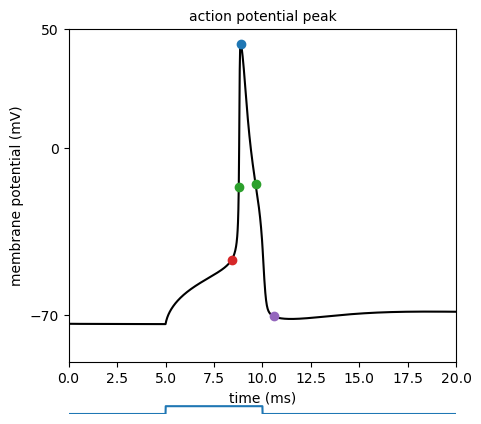

In [13]:
# threshold

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 5
stim.amp = 1.5
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = .01
h.finitialize()
h.continuerun(50 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_grad = np.gradient(v_soma)
smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy), 101, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t.as_numpy()) > 20)[0][0]+1

ap_thresh = v_soma[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

fig, ax = plt.subplots(2,1, figsize=(5,5), height_ratios=[1, 0.05])
ax[0].plot(t, v_soma, color='k')
ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_title('action potential peak')
ax[0].plot(t[np.argmax(v_soma)], ap_peak, 'o', color='tab:blue')
ax[0].set_ylim([-90, 50])
ax[0].set_yticks([-70,0, 50])

ax[0].plot(t[ap_thresh_idx], ap_thresh, 'o', color='tab:red')



# Width at halfmax
ap_trough = np.argmin(v_soma.as_numpy()[np.argmax(v_soma):])

half_max = np.min(v_soma.as_numpy()) + (np.max(v_soma.as_numpy())-np.min(v_soma.as_numpy()))/2
idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):int(ap_trough+np.argmax(v_soma))]-half_max))

ephys_measures['ap_width'] = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]

v2 = np.gradient(np.gradient(v_soma.as_numpy()))

ax[0].plot(t.as_numpy()[idx1+ap_thresh_idx],v_soma.as_numpy()[idx1+ap_thresh_idx],'o', color='tab:green')
ax[0].plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o', color='tab:green')
ax[0].set_xlim([0, 20])
ax[1].plot(t,clamp_current)
ax[0].set_xlabel('time (ms)')
ax[1].set_xticks(np.arange(0, 25, 5))
ax[1].set_xlim([0, 20])
ax[1].set_ylabel('current (nA)')
ax[1].set_ylim([0, 3.2])
ax[1].set_axis_off()
ap_hw = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]

v2 = np.gradient(np.gradient(smooth_v))


start = int(ap)
stop = np.argmax(np.abs(t.as_numpy()- 10))

elbow_p = int(np.argmin(v_soma.as_numpy()[start:stop]) + start)

f_AHP = v_soma.as_numpy()[elbow_p] - ap_thresh


#ax[0].plot(t.as_numpy()[elbow_p], v_soma.as_numpy()[elbow_p], 'o', color='tab:purple')

# upstroke: mean of dV/dt between AP threshold and AP peak
 
upstroke = np.mean(np.gradient(v_soma.as_numpy()[ap_thresh_idx:int(ap)]))

# downstroke: minimum value of dV/dt between AP peak and trough

pk, properties = find_peaks(smooth_v[int(ap)+1:], height=0)

ap_trough = int(ap+1+pk[0])
ax[0].plot(t.as_numpy()[ap_trough], v_soma.as_numpy()[ap_trough], 'o', color='tab:purple')

downstroke = np.mean(np.gradient(v_soma.as_numpy()[int(ap):ap_trough]))

ephys_measures['upstroke_downstroke'] = np.abs(upstroke/downstroke)

smooth_v = signal.savgol_filter(np.diff(v_soma.as_numpy()), 101, 3)

ap_thresh_idx = np.where(smooth_v/np.diff(t.as_numpy()) > 20)[0][0]+1
ephys_measures['ap_threshold'] = v_soma[ap_thresh_idx]

fig.savefig(figpth+'ap_measures.png')
fig.savefig(figpth+'ap_measures.svg')


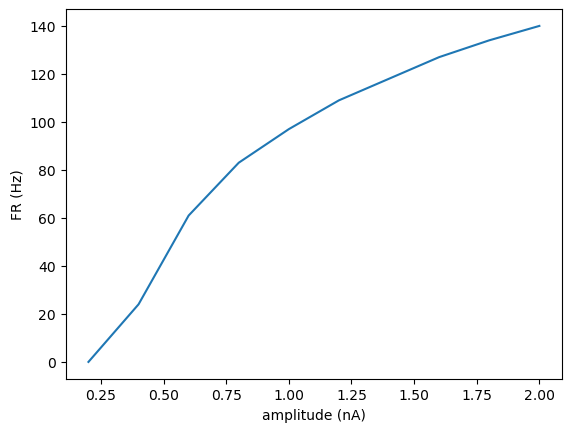

In [14]:
# FR slope
l_stim = 1000

ampl = np.linspace(.2, 2.0, 10)

soma_v = np.zeros((len(ampl),int(1/h.dt*l_stim+1)))
fr = np.zeros_like(ampl)

for i,amp in enumerate(ampl):

    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize()
    h.continuerun((l_stim+stim.delay)* ms)

    pk = find_peaks(v_soma, height=0)

    fr[i] = len(pk[0])


fig, ax = plt.subplots()
ax.plot(ampl,fr)
ax.set_ylabel('FR (Hz)')
ax.set_xlabel('amplitude (nA)')

pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

fig.savefig(figpth+'FR_slope.png')
fig.savefig(figpth+'FR_slope.svg')




In [15]:
ephys_measures['FR_slope']

np.float64(0.07506060606060605)

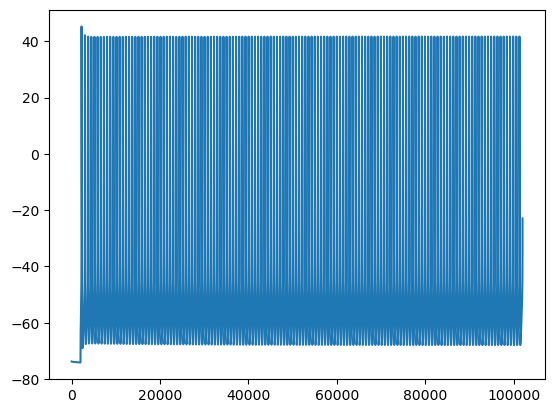

In [16]:
plt.plot(v_soma)

In [17]:
pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.max(np.gradient(fr))#np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

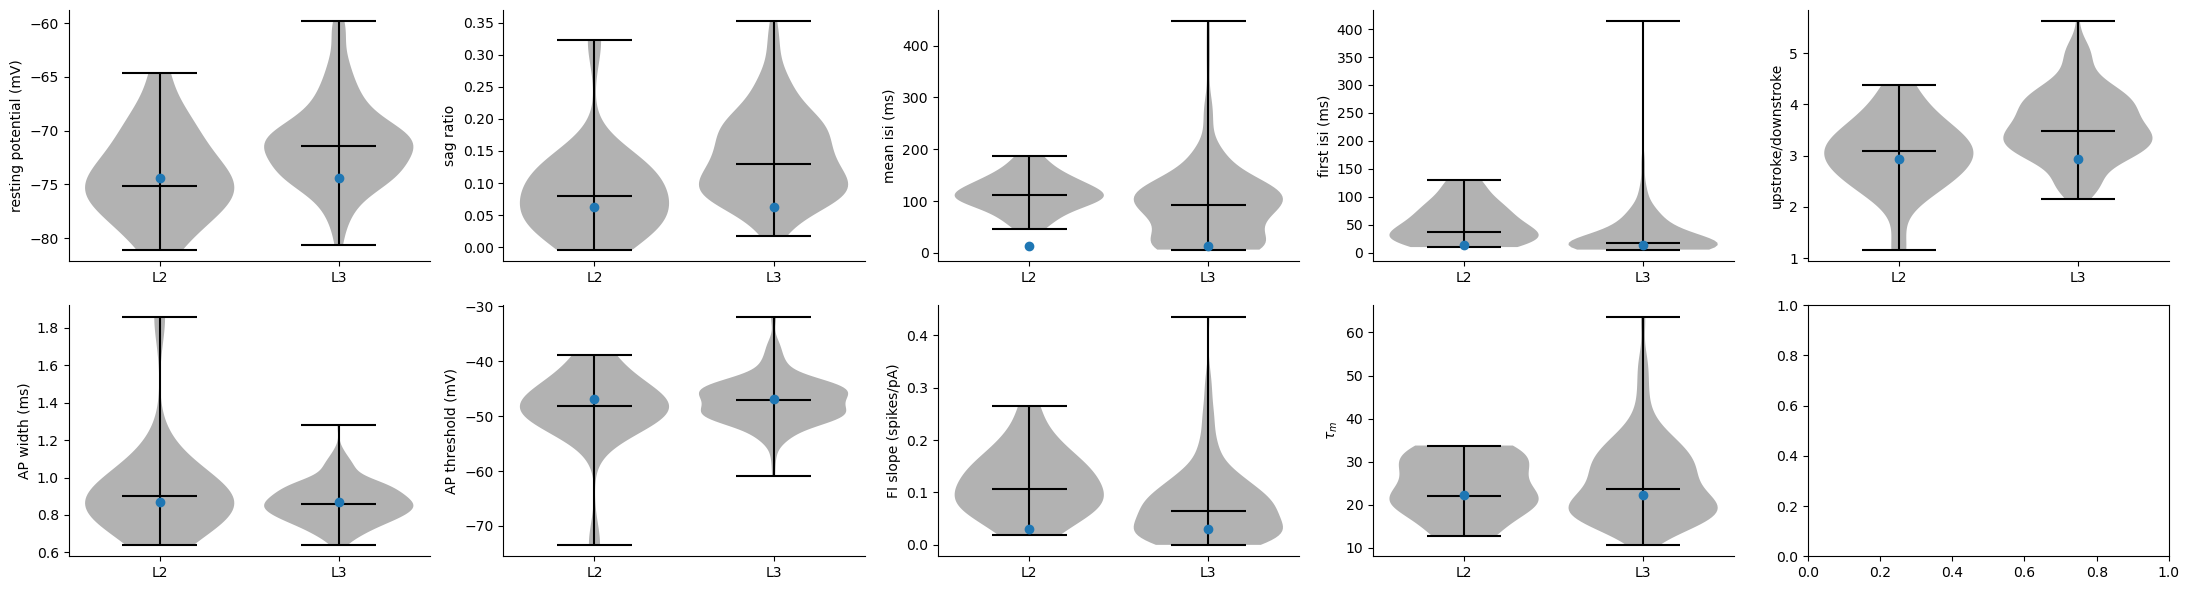

In [18]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope', 'tau']
label = ['resting potential (mV)', 'sag ratio', 'mean isi (ms)', 'first isi (ms)', 'upstroke/downstroke', 'AP width (ms)', 'AP threshold (mV)', 'FI slope (spikes/pA)', r'$\tau_{m}$']
ylims = [(-85,-50), (-0.1,.4), (0, 450), (0, 450), (1, 6), (0, 2), (-75, -25), (0, 0.5), (0, 65)]
fig, ax = plt.subplots(2,5, figsize=(22,6))

ax = ax.ravel()
for i,m in enumerate(measures):

    data = [l2_allen[m].dropna(),l3_allen[m].dropna()]
    v = ax[i].violinplot(data, positions=[1.2,1.8], vert=True, showmeans=False,
                  showmedians=True)
    # ax[i].set_xticklabels(['L2', 'L3'])

    ax[i].plot(1.2, ephys_measures[m], 'o', color='tab:blue')
    ax[i].plot(1.8, ephys_measures[m], 'o', color='tab:blue')
    ax[i].set_ylabel(label[i])
    ax[i].set_xticks([1.2,1.8],labels=['L2', 'L3'])
    #ax[i].set_ylim(ylims[i])

    # if i in [2,3]:
    #     ax[i].set_yticks(np.linspace(ylims[i][0], ylims[i][1], 4))
    # else:
    #     ax[i].set_yticks(np.linspace(ylims[i][0], ylims[i][1], 3))
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)

    for pc in v['bodies']:
        pc.set_facecolor('black')
    v['cbars'].set_color('black')
    v['cmaxes'].set_color('black')
    v['cmins'].set_color('black')
    v['cmedians'].set_color('black')

fig.tight_layout()
fig.savefig(figpth+'l23_cell_vs_allen.png')
fig.savefig(figpth+'l23_cell_vs_allen.svg')

In [19]:
ephys_measures['tau']

np.float32(22.286007)

In [20]:
l2_allen['tau']

569095789    14.977079
528706755    33.742707
616647103          NaN
508421103    31.221275
637034000    12.753842
571500474    20.626604
614659629    20.512368
526714733    21.491333
571464200    32.288203
537204107    19.463903
525133308    27.841920
526727406    24.747483
539537094    28.526441
528602977    19.742124
529997668    31.389642
571654895    32.992448
488392806    21.054303
541563728    21.926733
567747448    27.728556
576107598    12.873690
Name: tau, dtype: float64

In [21]:
ephys_measures['FR_slope']

np.float64(0.0305)

In [22]:
ephys_measures['mean_isi']

np.float64(13.619583333321522)